In [13]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/muhammadwaqas023/predictive-maintenance-oil-and-gas-pipeline-data/market_pipe_thickness_loss_dataset.csv


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/datasets/muhammadwaqas023/predictive-maintenance-oil-and-gas-pipeline-data/market_pipe_thickness_loss_dataset.csv


In [16]:
file_path = "/kaggle/input/datasets/muhammadwaqas023/predictive-maintenance-oil-and-gas-pipeline-data/market_pipe_thickness_loss_dataset.csv"

df = pd.read_csv(file_path)

df.head()

,Pipe_Size_mm,Thickness_mm,Material,Grade,Max_Pressure_psi,Temperature_C,Corrosion_Impact_Percent,Thickness_Loss_mm,Material_Loss_Percent,Time_Years,Condition
0,800,15.48,Carbon Steel,ASTM A333 Grade 6,300,84.9,16.04,4.91,31.72,2,Moderate
1,800,22.00,PVC,ASTM A106 Grade B,150,14.1,7.38,7.32,33.27,4,Critical
2,400,12.05,Carbon Steel,API 5L X52,2500,0.6,2.12,6.32,52.45,7,Critical
3,1500,38.72,Carbon Steel,API 5L X42,1500,52.7,5.58,6.20,16.01,19,Critical
4,1500,24.32,HDPE,API 5L X65,1500,11.7,12.29,8.58,35.28,20,Critical


In [17]:
df.columns

Index(['Pipe_Size_mm', 'Thickness_mm', 'Material', 'Grade', 'Max_Pressure_psi',
       'Temperature_C', 'Corrosion_Impact_Percent', 'Thickness_Loss_mm',
       'Material_Loss_Percent', 'Time_Years', 'Condition'],
      dtype='object')

In [18]:
df["Condition"].value_counts()

Condition
Critical    487
Moderate    299
Normal      214
Name: count, dtype: int64

In [19]:
df["Condition"].value_counts(normalize=True) * 100

Condition
Critical    48.7
Moderate    29.9
Normal      21.4
Name: proportion, dtype: float64

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pipe_Size_mm              1000 non-null   int64  
 1   Thickness_mm              1000 non-null   float64
 2   Material                  1000 non-null   object 
 3   Grade                     1000 non-null   object 
 4   Max_Pressure_psi          1000 non-null   int64  
 5   Temperature_C             1000 non-null   float64
 6   Corrosion_Impact_Percent  1000 non-null   float64
 7   Thickness_Loss_mm         1000 non-null   float64
 8   Material_Loss_Percent     1000 non-null   float64
 9   Time_Years                1000 non-null   int64  
 10  Condition                 1000 non-null   object 
dtypes: float64(5), int64(3), object(3)
memory usage: 86.1+ KB


In [21]:
df.isnull().sum()

Pipe_Size_mm                0
Thickness_mm                0
Material                    0
Grade                       0
Max_Pressure_psi            0
Temperature_C               0
Corrosion_Impact_Percent    0
Thickness_Loss_mm           0
Material_Loss_Percent       0
Time_Years                  0
Condition                   0
dtype: int64

In [22]:
df.describe()

,Pipe_Size_mm,Thickness_mm,Max_Pressure_psi,Temperature_C,Corrosion_Impact_Percent,Thickness_Loss_mm,Material_Loss_Percent,Time_Years
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,522.000000,16.073530,1004.100000,42.595600,9.745990,4.886300,46.747560,12.961000
std,443.703587,10.548358,812.843099,41.127071,5.817492,2.901123,46.602553,7.135993
min,50.000000,3.000000,150.000000,-50.000000,0.000000,0.010000,0.080000,1.000000
25%,150.000000,7.357500,300.000000,13.400000,4.492500,2.365000,15.665000,7.000000
50%,300.000000,12.930000,900.000000,41.200000,9.720000,4.915000,31.660000,13.000000
75%,800.000000,23.027500,1500.000000,69.150000,14.832500,7.432500,61.035000,19.000000
max,1500.000000,49.530000,2500.000000,149.700000,20.000000,9.990000,318.750000,25.000000


In [23]:
df["Material"].value_counts()

Material
Fiberglass         219
Carbon Steel       210
Stainless Steel    201
PVC                186
HDPE               184
Name: count, dtype: int64

In [24]:
df["Grade"].value_counts()

Grade
ASTM A333 Grade 6    228
ASTM A106 Grade B    212
API 5L X52           191
API 5L X42           186
API 5L X65           183
Name: count, dtype: int64

In [25]:
pd.crosstab(df["Material"], df["Condition"])

Condition,Critical,Moderate,Normal
Material,,,
Carbon Steel,97,53,60
Fiberglass,103,79,37
HDPE,88,57,39
PVC,104,47,35
Stainless Steel,95,63,43


In [26]:
pd.crosstab(
    df["Material"],
    df["Condition"],
    normalize="index"
) * 100

Condition,Critical,Moderate,Normal
Material,,,
Carbon Steel,46.190476,25.238095,28.571429
Fiberglass,47.031963,36.073059,16.894977
HDPE,47.826087,30.978261,21.195652
PVC,55.913978,25.268817,18.817204
Stainless Steel,47.263682,31.343284,21.393035


In [27]:
pd.crosstab(
    df["Grade"],
    df["Condition"],
    normalize="index"
) * 100

Condition,Critical,Moderate,Normal
Grade,,,
API 5L X42,45.161290,31.182796,23.655914
API 5L X52,52.879581,31.413613,15.706806
API 5L X65,53.005464,27.322404,19.672131
ASTM A106 Grade B,42.452830,33.490566,24.056604
ASTM A333 Grade 6,50.438596,26.315789,23.245614


In [28]:
df.groupby("Condition").mean(numeric_only=True)

,Pipe_Size_mm,Thickness_mm,Max_Pressure_psi,Temperature_C,Corrosion_Impact_Percent,Thickness_Loss_mm,Material_Loss_Percent,Time_Years
Condition,,,,,,,,
Critical,557.494867,16.736694,1004.414784,43.252567,9.794702,7.458172,70.153018,12.792608
Moderate,464.882943,14.857191,1017.224080,40.078595,9.589097,3.533010,35.758562,13.478261
Normal,521.028037,16.263832,985.046729,44.617290,9.854346,0.924299,8.837523,12.621495


In [29]:
df.groupby("Condition")["Thickness_Loss_mm"].agg(
    ["count", "mean", "min", "max"]
)

,count,mean,min,max
Condition,,,,
Critical,487,7.458172,5.01,9.99
Moderate,299,3.533010,2.04,5.00
Normal,214,0.924299,0.01,1.99


In [30]:
df.groupby("Condition")["Material_Loss_Percent"].agg(
    ["count", "mean", "min", "max"]
)

,count,mean,min,max
Condition,,,,
Critical,487,70.153018,10.77,318.75
Moderate,299,35.758562,5.53,137.67
Normal,214,8.837523,0.08,42.92


In [31]:
df.corr(numeric_only=True)

,Pipe_Size_mm,Thickness_mm,Max_Pressure_psi,Temperature_C,Corrosion_Impact_Percent,Thickness_Loss_mm,Material_Loss_Percent,Time_Years
Pipe_Size_mm,1.000000,0.907295,0.005314,0.033515,-0.029507,0.063189,-0.486962,-0.038725
Thickness_mm,0.907295,1.000000,0.031811,0.035808,-0.035593,0.049979,-0.535069,-0.054131
Max_Pressure_psi,0.005314,0.031811,1.000000,0.011480,-0.024628,0.026025,0.007957,0.061999
Temperature_C,0.033515,0.035808,0.011480,1.000000,-0.012171,0.010826,0.004227,-0.024172
Corrosion_Impact_Percent,-0.029507,-0.035593,-0.024628,-0.012171,1.000000,0.008548,0.026738,-0.024244
Thickness_Loss_mm,0.063189,0.049979,0.026025,0.010826,0.008548,1.000000,0.576865,-0.012600
Material_Loss_Percent,-0.486962,-0.535069,0.007957,0.004227,0.026738,0.576865,1.000000,0.006085
Time_Years,-0.038725,-0.054131,0.061999,-0.024172,-0.024244,-0.012600,0.006085,1.000000


In [32]:
pd.crosstab(
    pd.cut(
        df["Thickness_Loss_mm"],
        bins=[0, 2, 5, 10],
        labels=["0-2", "2-5", "5-10"],
        include_lowest=True
    ),
    df["Condition"]
)

Condition,Critical,Moderate,Normal
Thickness_Loss_mm,,,
0-2,0,0,214
2-5,0,299,0
5-10,487,0,0


In [33]:
df.groupby("Condition")["Material_Loss_Percent"].agg(
    ["count", "mean", "min", "max"]
)

,count,mean,min,max
Condition,,,,
Critical,487,70.153018,10.77,318.75
Moderate,299,35.758562,5.53,137.67
Normal,214,8.837523,0.08,42.92


In [34]:
df.groupby("Condition").mean(numeric_only=True).T

Condition,Critical,Moderate,Normal
Pipe_Size_mm,557.494867,464.882943,521.028037
Thickness_mm,16.736694,14.857191,16.263832
Max_Pressure_psi,1004.414784,1017.224080,985.046729
Temperature_C,43.252567,40.078595,44.617290
Corrosion_Impact_Percent,9.794702,9.589097,9.854346
Thickness_Loss_mm,7.458172,3.533010,0.924299
Material_Loss_Percent,70.153018,35.758562,8.837523
Time_Years,12.792608,13.478261,12.621495


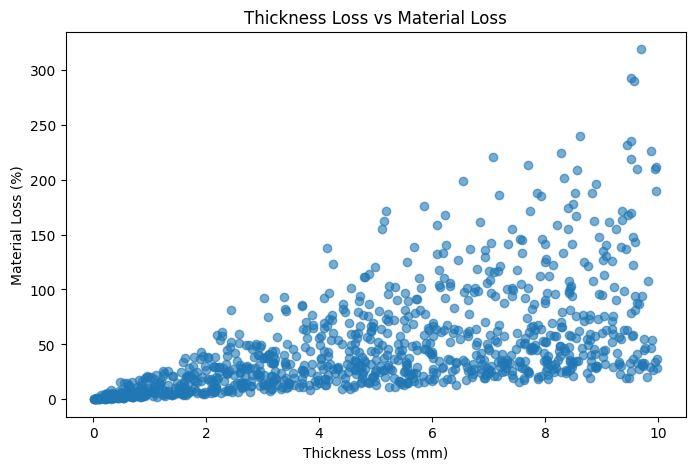

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Thickness_Loss_mm"],
    df["Material_Loss_Percent"],
    alpha=0.6
)

plt.xlabel("Thickness Loss (mm)")
plt.ylabel("Material Loss (%)")
plt.title("Thickness Loss vs Material Loss")

plt.show()

In [36]:
df[["Thickness_Loss_mm", "Material_Loss_Percent"]].describe()

,Thickness_Loss_mm,Material_Loss_Percent
count,1000.000000,1000.000000
mean,4.886300,46.747560
std,2.901123,46.602553
min,0.010000,0.080000
25%,2.365000,15.665000
50%,4.915000,31.660000
75%,7.432500,61.035000
max,9.990000,318.750000


In [37]:
df[["Thickness_Loss_mm", "Material_Loss_Percent"]].corr()

,Thickness_Loss_mm,Material_Loss_Percent
Thickness_Loss_mm,1.000000,0.576865
Material_Loss_Percent,0.576865,1.000000


In [38]:
# Target
y = df["Condition"]

# Features for Baseline Model
X_baseline = df.drop(columns=["Condition"])

# Features for Leakage-Aware Model
X_no_leakage = df.drop(columns=["Condition", "Thickness_Loss_mm"])

print("Target shape:", y.shape)
print("Baseline features shape:", X_baseline.shape)
print("Leakage-aware features shape:", X_no_leakage.shape)

Target shape: (1000,)
Baseline features shape: (1000, 10)
Leakage-aware features shape: (1000, 9)


In [39]:
from sklearn.model_selection import train_test_split

# Split data while preserving the class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X_no_leakage,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (800, 9)
Testing features shape: (200, 9)
Training target shape: (800,)
Testing target shape: (200,)


In [40]:
# Check class distribution in the training set
print("Training set:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting set:")
print(y_test.value_counts(normalize=True) * 100)

Training set:
Condition
Critical    48.750
Moderate    29.875
Normal      21.375
Name: proportion, dtype: float64

Testing set:
Condition
Critical    48.5
Moderate    30.0
Normal      21.5
Name: proportion, dtype: float64


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical columns
categorical_features = ["Material", "Grade"]

# Create the encoder
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

# Fit the encoder only on the training data
X_train_encoded = preprocessor.fit_transform(X_train)

# Transform the test data using the same encoder
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (800, 17)
Encoded testing shape: (200, 17)


In [42]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Train the model
model.fit(X_train_encoded, y_train)

print("Model training completed.")

Model training completed.


In [43]:
# Make predictions on the test set
y_pred = model.predict(X_test_encoded)

print("First 20 predictions:")
print(y_pred[:20])

First 20 predictions:
['Normal' 'Moderate' 'Normal' 'Normal' 'Normal' 'Critical' 'Critical'
 'Critical' 'Normal' 'Critical' 'Moderate' 'Normal' 'Critical' 'Critical'
 'Moderate' 'Critical' 'Moderate' 'Critical' 'Critical' 'Moderate']


In [44]:
# Compare actual and predicted values for the first 20 test records

comparison = pd.DataFrame({
    "Actual": y_test.iloc[:20].values,
    "Predicted": y_pred[:20]
})

comparison

,Actual,Predicted
0,Normal,Normal
1,Critical,Moderate
2,Normal,Normal
3,Normal,Normal
4,Normal,Normal
5,Moderate,Critical
6,Critical,Critical
7,Moderate,Critical
8,Normal,Normal
9,Moderate,Critical


In [45]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy (%): {accuracy * 100:.2f}%")

Accuracy: 0.8750
Accuracy (%): 87.50%


              precision    recall  f1-score   support

    Critical       0.86      0.97      0.91        97
    Moderate       0.84      0.72      0.77        60
      Normal       0.95      0.88      0.92        43

    accuracy                           0.88       200
   macro avg       0.89      0.86      0.87       200
weighted avg       0.88      0.88      0.87       200

Confusion Matrix:
[[94  3  0]
 [15 43  2]
 [ 0  5 38]]


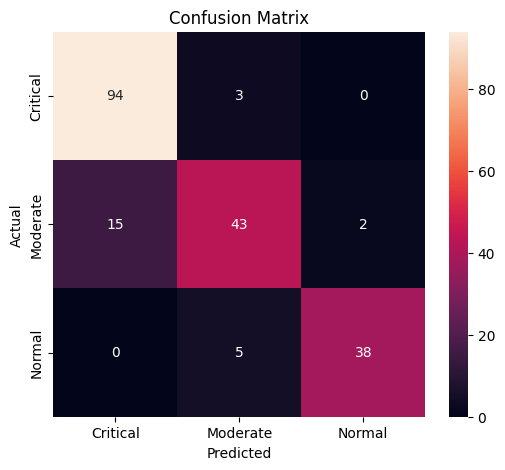

In [46]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Define class order
class_names = ["Critical", "Moderate", "Normal"]

# Classification Report
print(classification_report(y_test, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=class_names)

print("Confusion Matrix:")
print(cm)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [47]:
import pandas as pd

# Get feature names after encoding
feature_names = preprocessor.get_feature_names_out()

# Create Feature Importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                                  Feature  Importance
15       remainder__Material_Loss_Percent    0.468448
11                remainder__Thickness_mm    0.131598
10                remainder__Pipe_Size_mm    0.073985
13               remainder__Temperature_C    0.070836
14    remainder__Corrosion_Impact_Percent    0.070150
16                  remainder__Time_Years    0.057373
12            remainder__Max_Pressure_psi    0.036573
5           categorical__Grade_API 5L X42    0.011368
0      categorical__Material_Carbon Steel    0.010507
6           categorical__Grade_API 5L X52    0.010186
1        categorical__Material_Fiberglass    0.009454
7           categorical__Grade_API 5L X65    0.008540
8    categorical__Grade_ASTM A106 Grade B    0.008529
3               categorical__Material_PVC    0.008437
2              categorical__Material_HDPE    0.008174
4   categorical__Material_Stainless Steel    0.008052
9    categorical__Grade_ASTM A333 Grade 6    0.007789


In [48]:
import pandas as pd

# Check Material Loss Percent by Condition
loss_by_condition = df.groupby("Condition")["Material_Loss_Percent"].agg(
    ["count", "min", "max", "mean", "median"]
)

print(loss_by_condition)

           count    min     max       mean  median
Condition                                         
Critical     487  10.77  318.75  70.153018  52.230
Moderate     299   5.53  137.67  35.758562  29.010
Normal       214   0.08   42.92   8.837523   5.705


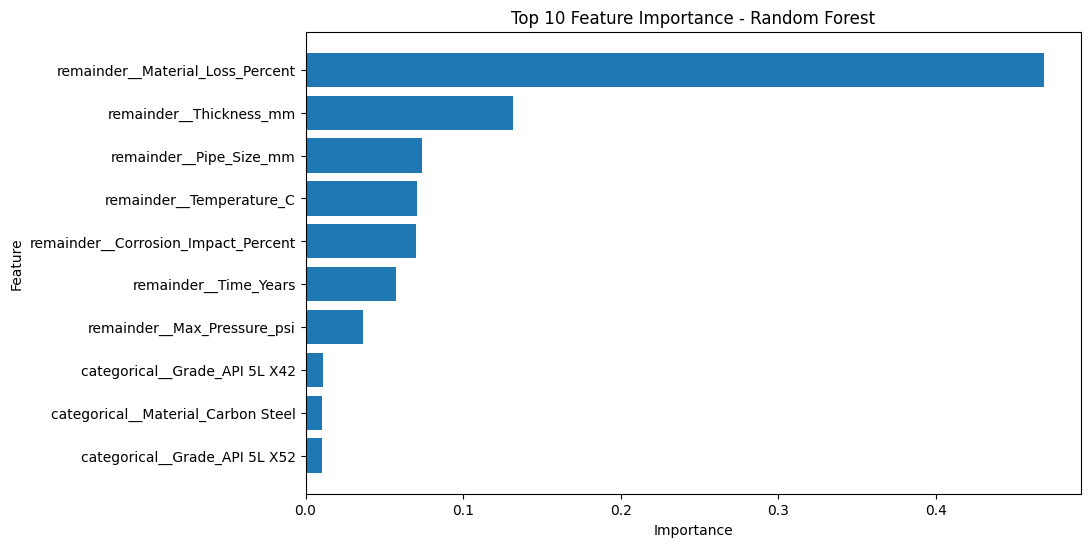

In [49]:
import matplotlib.pyplot as plt

# Select top features
top_features = feature_importance.head(10)

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importance - Random Forest")

plt.gca().invert_yaxis()

plt.show()

In [50]:
from sklearn.metrics import accuracy_score

# Predictions on training data
y_train_pred = model.predict(X_train_encoded)

# Predictions on test data
y_test_pred = model.predict(X_test_encoded)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Train Accuracy:", round(train_accuracy, 4))
print("Test Accuracy:", round(test_accuracy, 4))

Train Accuracy: 1.0
Test Accuracy: 0.875


In [51]:
from sklearn.ensemble import RandomForestClassifier

model_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

model_tuned.fit(X_train_encoded, y_train)

print("Tuned model training completed.")

Tuned model training completed.


In [52]:
from sklearn.metrics import accuracy_score

# Predictions on training data
y_train_pred_tuned = model_tuned.predict(X_train_encoded)

# Predictions on test data
y_test_pred_tuned = model_tuned.predict(X_test_encoded)

# Calculate accuracy
train_accuracy_tuned = accuracy_score(y_train, y_train_pred_tuned)
test_accuracy_tuned = accuracy_score(y_test, y_test_pred_tuned)

print("Tuned Train Accuracy:", round(train_accuracy_tuned, 4))
print("Tuned Test Accuracy:", round(test_accuracy_tuned, 4))

Tuned Train Accuracy: 0.9812
Tuned Test Accuracy: 0.84


In [53]:
from sklearn.ensemble import RandomForestClassifier

model_500 = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

model_500.fit(X_train_encoded, y_train)

print("Model with 500 trees training completed.")

Model with 500 trees training completed.


In [54]:
from sklearn.metrics import accuracy_score

# Predictions
y_train_pred_500 = model_500.predict(X_train_encoded)
y_test_pred_500 = model_500.predict(X_test_encoded)

# Accuracy
train_accuracy_500 = accuracy_score(y_train, y_train_pred_500)
test_accuracy_500 = accuracy_score(y_test, y_test_pred_500)

print("500 Trees - Train Accuracy:", round(train_accuracy_500, 4))
print("500 Trees - Test Accuracy:", round(test_accuracy_500, 4))

500 Trees - Train Accuracy: 1.0
500 Trees - Test Accuracy: 0.895


              precision    recall  f1-score   support

    Critical       0.90      0.97      0.93        97
    Moderate       0.85      0.78      0.82        60
      Normal       0.95      0.88      0.92        43

    accuracy                           0.90       200
   macro avg       0.90      0.88      0.89       200
weighted avg       0.89      0.90      0.89       200

Confusion Matrix:
[[94  3  0]
 [11 47  2]
 [ 0  5 38]]


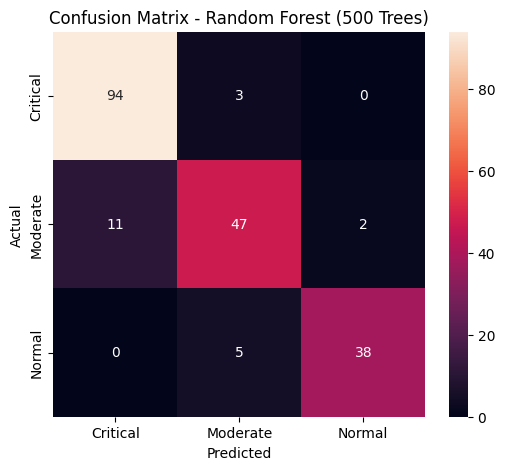

In [55]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

class_names = ["Critical", "Moderate", "Normal"]

# Classification Report
print(classification_report(
    y_test,
    y_test_pred_500,
    target_names=class_names
))

# Confusion Matrix
cm_500 = confusion_matrix(
    y_test,
    y_test_pred_500,
    labels=class_names
)

print("Confusion Matrix:")
print(cm_500)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_500,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest (500 Trees)")

plt.show()

In [56]:
from sklearn.ensemble import RandomForestClassifier

model_leaf = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=2,
    random_state=42
)

model_leaf.fit(X_train_encoded, y_train)

print("Model with min_samples_leaf=2 training completed.")

Model with min_samples_leaf=2 training completed.


In [57]:
from sklearn.metrics import accuracy_score

# Predictions
y_train_pred_leaf = model_leaf.predict(X_train_encoded)
y_test_pred_leaf = model_leaf.predict(X_test_encoded)

# Accuracy
train_accuracy_leaf = accuracy_score(y_train, y_train_pred_leaf)
test_accuracy_leaf = accuracy_score(y_test, y_test_pred_leaf)

print("min_samples_leaf=2 - Train Accuracy:", round(train_accuracy_leaf, 4))
print("min_samples_leaf=2 - Test Accuracy:", round(test_accuracy_leaf, 4))

min_samples_leaf=2 - Train Accuracy: 1.0
min_samples_leaf=2 - Test Accuracy: 0.89


In [58]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    model_500,
    X_train_encoded,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross-Validation Scores:", cv_scores)
print("Mean CV Accuracy:", round(cv_scores.mean(), 4))
print("CV Standard Deviation:", round(cv_scores.std(), 4))

Cross-Validation Scores: [0.875   0.85625 0.8875  0.85625 0.825  ]
Mean CV Accuracy: 0.86
CV Standard Deviation: 0.0211


In [59]:
import pandas as pd

# Create error analysis DataFrame
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test
error_analysis["Predicted"] = y_test_pred_500

# Keep only incorrect predictions
errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
]

print("Number of incorrect predictions:", len(errors))
print("Number of correct predictions:", len(X_test) - len(errors))

print("\nError Types:")
print(
    errors.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
)

Number of incorrect predictions: 21
Number of correct predictions: 179

Error Types:
     Actual Predicted  Count
0  Critical  Moderate      3
1  Moderate  Critical     11
2  Moderate    Normal      2
3    Normal  Moderate      5


In [60]:
# Display the incorrect predictions
print(
    errors[
        [
            "Actual",
            "Predicted",
            "Thickness_mm",
            "Pipe_Size_mm",
            "Temperature_C",
            "Max_Pressure_psi",
            "Material_Loss_Percent",
            "Corrosion_Impact_Percent",
            "Time_Years",
            "Material",
            "Grade"
        ]
    ].to_string(index=False)
)

  Actual Predicted  Thickness_mm  Pipe_Size_mm  Temperature_C  Max_Pressure_psi  Material_Loss_Percent  Corrosion_Impact_Percent  Time_Years        Material             Grade
Critical  Moderate         15.05           300           37.9               600                  35.81                      6.60          12            HDPE        API 5L X42
Moderate  Critical         15.72          1000          124.9              2500                  27.61                      5.20          22    Carbon Steel ASTM A333 Grade 6
Moderate  Critical          4.29            50           37.2               600                 113.75                     19.35          19             PVC ASTM A106 Grade B
Moderate  Critical         20.01           500            5.6               300                  24.94                      2.64          23      Fiberglass ASTM A106 Grade B
Moderate  Critical          5.26            50           61.1              2500                  89.54                     16

In [61]:
# Get prediction probabilities
y_test_proba = model_500.predict_proba(X_test_encoded)

# Get class names in the same order as the model
model_classes = model_500.classes_

# Create probability DataFrame
probabilities = pd.DataFrame(
    y_test_proba,
    columns=model_classes,
    index=X_test.index
)

# Add actual and predicted labels
probabilities["Actual"] = y_test
probabilities["Predicted"] = y_test_pred_500

# Keep only incorrect predictions
error_probabilities = probabilities[
    probabilities["Actual"] != probabilities["Predicted"]
]

print(
    error_probabilities.to_string()
)

     Critical  Moderate  Normal    Actual Predicted
998     0.378     0.582   0.040  Critical  Moderate
344     0.594     0.334   0.072  Moderate  Critical
377     0.584     0.396   0.020  Moderate  Critical
391     0.496     0.476   0.028  Moderate  Critical
347     0.606     0.280   0.114  Moderate  Critical
512     0.150     0.668   0.182    Normal  Moderate
881     0.594     0.370   0.036  Moderate  Critical
418     0.492     0.460   0.048  Moderate  Critical
630     0.140     0.534   0.326    Normal  Moderate
917     0.486     0.502   0.012  Critical  Moderate
25      0.090     0.484   0.426    Normal  Moderate
166     0.530     0.388   0.082  Moderate  Critical
378     0.544     0.386   0.070  Moderate  Critical
646     0.106     0.644   0.250    Normal  Moderate
520     0.616     0.352   0.032  Moderate  Critical
614     0.480     0.496   0.024  Critical  Moderate
385     0.108     0.530   0.362    Normal  Moderate
624     0.494     0.462   0.044  Moderate  Critical
626     0.09

In [62]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train_encoded)

# Transform test data
X_test_scaled = scaler.transform(X_test_encoded)

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train model
logistic_model.fit(X_train_scaled, y_train)

print("Scaled Logistic Regression training completed.")

Scaled Logistic Regression training completed.


In [63]:
from sklearn.metrics import accuracy_score

# Predictions
y_train_pred_logistic = logistic_model.predict(X_train_scaled)
y_test_pred_logistic = logistic_model.predict(X_test_scaled)

# Accuracy
train_accuracy_logistic = accuracy_score(
    y_train,
    y_train_pred_logistic
)

test_accuracy_logistic = accuracy_score(
    y_test,
    y_test_pred_logistic
)

print(
    "Logistic Regression - Train Accuracy:",
    round(train_accuracy_logistic, 4)
)

print(
    "Logistic Regression - Test Accuracy:",
    round(test_accuracy_logistic, 4)
)

Logistic Regression - Train Accuracy: 0.8225
Logistic Regression - Test Accuracy: 0.8


              precision    recall  f1-score   support

    Critical       0.81      0.94      0.87        97
    Moderate       0.74      0.58      0.65        60
      Normal       0.85      0.79      0.82        43

    accuracy                           0.80       200
   macro avg       0.80      0.77      0.78       200
weighted avg       0.80      0.80      0.79       200

Confusion Matrix:
[[91  6  0]
 [19 35  6]
 [ 3  6 34]]


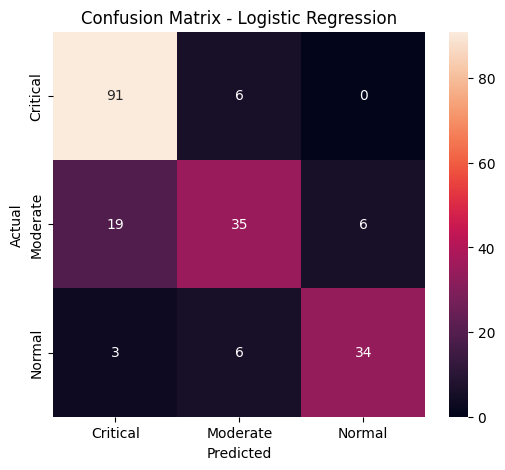

In [64]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

class_names = ["Critical", "Moderate", "Normal"]

# Classification Report
print(
    classification_report(
        y_test,
        y_test_pred_logistic,
        target_names=class_names
    )
)

# Confusion Matrix
cm_logistic = confusion_matrix(
    y_test,
    y_test_pred_logistic,
    labels=class_names
)

print("Confusion Matrix:")
print(cm_logistic)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

In [65]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train_encoded, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


In [66]:
from sklearn.metrics import accuracy_score

# Predictions
y_train_pred_tree = decision_tree.predict(X_train_encoded)
y_test_pred_tree = decision_tree.predict(X_test_encoded)

# Accuracy
train_accuracy_tree = accuracy_score(
    y_train,
    y_train_pred_tree
)

test_accuracy_tree = accuracy_score(
    y_test,
    y_test_pred_tree
)

print(
    "Decision Tree - Train Accuracy:",
    round(train_accuracy_tree, 4)
)

print(
    "Decision Tree - Test Accuracy:",
    round(test_accuracy_tree, 4)
)

Decision Tree - Train Accuracy: 1.0
Decision Tree - Test Accuracy: 0.895


              precision    recall  f1-score   support

    Critical       0.94      0.91      0.92        97
    Moderate       0.80      0.87      0.83        60
      Normal       0.95      0.91      0.93        43

    accuracy                           0.90       200
   macro avg       0.90      0.89      0.89       200
weighted avg       0.90      0.90      0.90       200

Confusion Matrix:
[[88  9  0]
 [ 6 52  2]
 [ 0  4 39]]


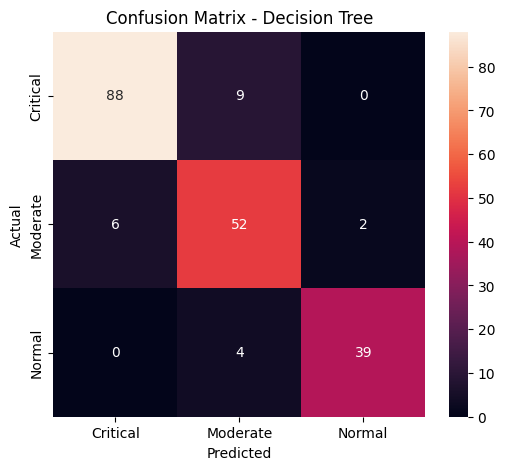

In [67]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

class_names = ["Critical", "Moderate", "Normal"]

# Classification Report
print(
    classification_report(
        y_test,
        y_test_pred_tree,
        target_names=class_names
    )
)

# Confusion Matrix
cm_tree = confusion_matrix(
    y_test,
    y_test_pred_tree,
    labels=class_names
)

print("Confusion Matrix:")
print(cm_tree)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Decision Tree")

plt.show()

In [68]:
from sklearn.model_selection import cross_val_score

cv_scores_tree = cross_val_score(
    decision_tree,
    X_train_encoded,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Decision Tree CV Scores:", cv_scores_tree)
print(
    "Decision Tree Mean CV Accuracy:",
    round(cv_scores_tree.mean(), 4)
)

print(
    "Decision Tree CV Standard Deviation:",
    round(cv_scores_tree.std(), 4)
)

Decision Tree CV Scores: [0.9     0.9125  0.8875  0.89375 0.9    ]
Decision Tree Mean CV Accuracy: 0.8988
Decision Tree CV Standard Deviation: 0.0083


In [69]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_tuned = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

decision_tree_tuned.fit(X_train_encoded, y_train)

print("Tuned Decision Tree training completed.")

Tuned Decision Tree training completed.


In [70]:
from sklearn.metrics import accuracy_score

# Predictions
y_train_pred_tree_tuned = decision_tree_tuned.predict(X_train_encoded)
y_test_pred_tree_tuned = decision_tree_tuned.predict(X_test_encoded)

# Accuracy
train_accuracy_tree_tuned = accuracy_score(
    y_train,
    y_train_pred_tree_tuned
)

test_accuracy_tree_tuned = accuracy_score(
    y_test,
    y_test_pred_tree_tuned
)

print(
    "Tuned Decision Tree - Train Accuracy:",
    round(train_accuracy_tree_tuned, 4)
)

print(
    "Tuned Decision Tree - Test Accuracy:",
    round(test_accuracy_tree_tuned, 4)
)

Tuned Decision Tree - Train Accuracy: 0.895
Tuned Decision Tree - Test Accuracy: 0.845


In [71]:
from sklearn.model_selection import cross_val_score

cv_scores_tree_tuned = cross_val_score(
    decision_tree_tuned,
    X_train_encoded,
    y_train,
    cv=5,
    scoring="accuracy"
)

print(
    "Tuned Decision Tree CV Scores:",
    cv_scores_tree_tuned
)

print(
    "Tuned Decision Tree Mean CV Accuracy:",
    round(cv_scores_tree_tuned.mean(), 4)
)

print(
    "Tuned Decision Tree CV Standard Deviation:",
    round(cv_scores_tree_tuned.std(), 4)
)

Tuned Decision Tree CV Scores: [0.8375  0.7875  0.86875 0.88125 0.8125 ]
Tuned Decision Tree Mean CV Accuracy: 0.8375
Tuned Decision Tree CV Standard Deviation: 0.0347


In [72]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_leaf = DecisionTreeClassifier(
    min_samples_leaf=2,
    random_state=42
)

decision_tree_leaf.fit(X_train_encoded, y_train)

print("Decision Tree with min_samples_leaf=2 training completed.")

Decision Tree with min_samples_leaf=2 training completed.


In [73]:
from sklearn.metrics import accuracy_score

# Predictions
y_train_pred_tree_leaf = decision_tree_leaf.predict(X_train_encoded)
y_test_pred_tree_leaf = decision_tree_leaf.predict(X_test_encoded)

# Accuracy
train_accuracy_tree_leaf = accuracy_score(
    y_train,
    y_train_pred_tree_leaf
)

test_accuracy_tree_leaf = accuracy_score(
    y_test,
    y_test_pred_tree_leaf
)

print(
    "Decision Tree (min_samples_leaf=2) - Train Accuracy:",
    round(train_accuracy_tree_leaf, 4)
)

print(
    "Decision Tree (min_samples_leaf=2) - Test Accuracy:",
    round(test_accuracy_tree_leaf, 4)
)

Decision Tree (min_samples_leaf=2) - Train Accuracy: 0.99
Decision Tree (min_samples_leaf=2) - Test Accuracy: 0.885


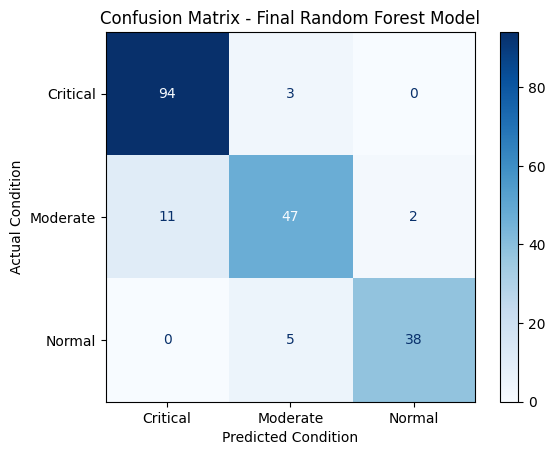

In [74]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_500,
    display_labels=class_names,
    cmap="Blues"
)

plt.title("Confusion Matrix - Final Random Forest Model")
plt.xlabel("Predicted Condition")
plt.ylabel("Actual Condition")
plt.show()

In [75]:
import joblib

# Save the final Random Forest model
joblib.dump(model_500, "final_random_forest_model.pkl")

# Save the preprocessor
joblib.dump(preprocessor, "preprocessor.pkl")

print("Model and preprocessor saved successfully.")

Model and preprocessor saved successfully.


In [76]:
# Select one sample from the original dataset
new_data = df.drop(columns=["Condition", "Thickness_Loss_mm"]).iloc[[0]]

print("New pipe data:")
print(new_data)

New pipe data:
   Pipe_Size_mm  Thickness_mm      Material              Grade  \
0           800         15.48  Carbon Steel  ASTM A333 Grade 6   

   Max_Pressure_psi  Temperature_C  Corrosion_Impact_Percent  \
0               300           84.9                     16.04   

   Material_Loss_Percent  Time_Years  
0                  31.72           2  


In [77]:
# Transform the new data using the same preprocessor
new_data_encoded = preprocessor.transform(new_data)

print("Encoded data shape:", new_data_encoded.shape)

Encoded data shape: (1, 17)


In [78]:
# Predict the condition of the new pipe
new_prediction = model_500.predict(new_data_encoded)

print("Predicted Condition:", new_prediction[0])

Predicted Condition: Moderate


In [79]:
# Prediction probabilities
new_prediction_proba = model_500.predict_proba(new_data_encoded)

probabilities_new = pd.DataFrame(
    new_prediction_proba,
    columns=model_500.classes_
)

print(probabilities_new.round(3))

   Critical  Moderate  Normal
0     0.276     0.704    0.02


In [80]:
def predict_pipe_condition(pipe_data):
    
    # Transform new data
    pipe_encoded = preprocessor.transform(pipe_data)
    
    # Prediction
    prediction = model_500.predict(pipe_encoded)[0]
    
    # Probabilities
    probabilities = model_500.predict_proba(pipe_encoded)[0]
    
    probability_df = pd.DataFrame({
        "Condition": model_500.classes_,
        "Probability": probabilities
    })
    
    probability_df["Probability"] = (
        probability_df["Probability"] * 100
    ).round(2)
    
    return prediction, probability_df

In [81]:
prediction, probability_df = predict_pipe_condition(new_data)

print("Predicted Condition:", prediction)
print("\nPrediction Probabilities:")
print(probability_df)

Predicted Condition: Moderate

Prediction Probabilities:
  Condition  Probability
0  Critical         27.6
1  Moderate         70.4
2    Normal          2.0


In [82]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Final pipeline
final_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=500,
            random_state=42
        ))
    ]
)

# Train the final pipeline on raw training data
final_pipeline.fit(X_train, y_train)

print("Final pipeline trained successfully.")

Final pipeline trained successfully.


In [83]:
from sklearn.metrics import accuracy_score

# Predictions using the final pipeline
y_test_pred_pipeline = final_pipeline.predict(X_test)

# Test accuracy
pipeline_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_pipeline
)

print(
    "Final Pipeline - Test Accuracy:",
    round(pipeline_test_accuracy, 4)
)

Final Pipeline - Test Accuracy: 0.895


In [84]:
# Predict using the final pipeline
new_prediction_pipeline = final_pipeline.predict(new_data)

# Prediction probabilities
new_probability_pipeline = final_pipeline.predict_proba(new_data)

# Create probability table
probability_pipeline_df = pd.DataFrame(
    new_probability_pipeline,
    columns=final_pipeline.classes_
)

probability_pipeline_df = (
    probability_pipeline_df * 100
).round(2)

print("Predicted Condition:", new_prediction_pipeline[0])

print("\nPrediction Probabilities:")
print(probability_pipeline_df)

Predicted Condition: Moderate

Prediction Probabilities:
   Critical  Moderate  Normal
0      27.6      70.4     2.0


In [85]:
import joblib

# Save the final pipeline
joblib.dump(
    final_pipeline,
    "final_pipe_condition_model.pkl"
)

print("Final pipeline saved successfully.")

Final pipeline saved successfully.


In [86]:
import joblib

# Load the saved pipeline
loaded_pipeline = joblib.load(
    "final_pipe_condition_model.pkl"
)

print("Saved pipeline loaded successfully.")

Saved pipeline loaded successfully.


In [87]:
new_prediction_loaded = loaded_pipeline.predict(new_data)
new_probability_loaded = loaded_pipeline.predict_proba(new_data)

probability_loaded_df = pd.DataFrame(
    new_probability_loaded,
    columns=loaded_pipeline.classes_
)

probability_loaded_df = (
    probability_loaded_df * 100
).round(2)

print("Predicted Condition:", new_prediction_loaded[0])

print("\nPrediction Probabilities:")
print(probability_loaded_df)

Predicted Condition: Moderate

Prediction Probabilities:
   Critical  Moderate  Normal
0      27.6      70.4     2.0


In [88]:
new_pipe = pd.DataFrame({
    "Pipe_Size_mm": [600],
    "Thickness_mm": [12.5],
    "Material": ["Carbon Steel"],
    "Grade": ["API 5L X52"],
    "Max_Pressure_psi": [250],
    "Temperature_C": [75],
    "Corrosion_Impact_Percent": [12],
    "Material_Loss_Percent": [25],
    "Time_Years": [4]
})

print("New Pipe Data:")
print(new_pipe)

New Pipe Data:
   Pipe_Size_mm  Thickness_mm      Material       Grade  Max_Pressure_psi  \
0           600          12.5  Carbon Steel  API 5L X52               250   

   Temperature_C  Corrosion_Impact_Percent  Material_Loss_Percent  Time_Years  
0             75                        12                     25           4  


In [89]:
new_prediction = loaded_pipeline.predict(new_pipe)
new_probability = loaded_pipeline.predict_proba(new_pipe)

probability_df = pd.DataFrame(
    new_probability,
    columns=loaded_pipeline.classes_
)

probability_df = (
    probability_df * 100
).round(2)

print("Predicted Condition:", new_prediction[0])

print("\nPrediction Probabilities:")
print(probability_df)

Predicted Condition: Moderate

Prediction Probabilities:
   Critical  Moderate  Normal
0      45.6      50.0     4.4


In [90]:
def predict_pipe_condition(pipe_data):
    
    # Prediction
    prediction = loaded_pipeline.predict(pipe_data)[0]
    
    # Prediction probabilities
    probabilities = loaded_pipeline.predict_proba(pipe_data)[0]
    
    # Create probability table
    probability_df = pd.DataFrame({
        "Condition": loaded_pipeline.classes_,
        "Probability": probabilities * 100
    })
    
    probability_df["Probability"] = (
        probability_df["Probability"].round(2)
    )
    
    return prediction, probability_df

In [91]:
new_pipe = pd.DataFrame({
    "Pipe_Size_mm": [600],
    "Thickness_mm": [12.5],
    "Material": ["Carbon Steel"],
    "Grade": ["API 5L X52"],
    "Max_Pressure_psi": [250],
    "Temperature_C": [75],
    "Corrosion_Impact_Percent": [12],
    "Material_Loss_Percent": [25],
    "Time_Years": [4]
})

print("New Pipe Data:")
print(new_pipe)

New Pipe Data:
   Pipe_Size_mm  Thickness_mm      Material       Grade  Max_Pressure_psi  \
0           600          12.5  Carbon Steel  API 5L X52               250   

   Temperature_C  Corrosion_Impact_Percent  Material_Loss_Percent  Time_Years  
0             75                        12                     25           4  


In [92]:
prediction, probability_df = predict_pipe_condition(new_pipe)

print("Predicted Condition:", prediction)

print("\nPrediction Probabilities:")
print(probability_df)

Predicted Condition: Moderate

Prediction Probabilities:
  Condition  Probability
0  Critical         45.6
1  Moderate         50.0
2    Normal          4.4


In [93]:
confidence = probability_df["Probability"].max()

print("Predicted Condition:", prediction)
print("Confidence:", confidence, "%")

if confidence < 60:
    print("Risk Assessment: Borderline prediction")
else:
    print("Risk Assessment: Higher confidence prediction")

Predicted Condition: Moderate
Confidence: 50.0 %
Risk Assessment: Borderline prediction
